# 13-CarEvaulation.ipynb

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Car Evaluation Database was derived from a simple hierarchical decision model originally developed for the demonstration of DEX, M. Bohanec, V. Rajkovic: Expert system for decision making. Sistemica 1(1), pp. 145-157, 1990.). The model evaluates cars according to the following concept structure:

CAR car acceptability . PRICE overall price . . buying buying price . . maint price of the maintenance . TECH technical characteristics . . COMFORT comfort . . . doors number of doors . . . persons capacity in terms of persons to carry . . . lug_boot the size of luggage boot . . safety estimated safety of the car

Input attributes are printed in lowercase. Besides the target concept (CAR), the model includes three intermediate concepts: PRICE, TECH, COMFORT. Every concept is in the original model related to its lower level descendants by a set of examples (for these examples sets see [Web Link]).

The Car Evaluation Database contains examples with the structural information removed, i.e., directly relates CAR to the six input attributes: buying, maint, doors, persons, lug_boot, safety.

Because of known underlying concept structure, this database may be particularly useful for testing constructive induction and structure discovery methods.

Attribute Information:

Class Values:

unacc, acc, good, vgood

Attributes:
buying: vhigh, high, med, low. maint: vhigh, high, med, low. doors: 2, 3, 4, 5more. persons: 2, 4, more. lug_boot: small, med, big. safety: low, med, high

In [10]:
df = pd.read_csv("13-car_evaluation.csv")

In [11]:
df.head()

,vhigh,vhigh.1,2,2.1,small,low,unacc
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   vhigh    1727 non-null   object
 1   vhigh.1  1727 non-null   object
 2   2        1727 non-null   object
 3   2.1      1727 non-null   object
 4   small    1727 non-null   object
 5   low      1727 non-null   object
 6   unacc    1727 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [13]:
df.describe()

,vhigh,vhigh.1,2,2.1,small,low,unacc
count,1727,1727,1727,1727,1727,1727,1727
unique,4,4,4,3,3,3,4
top,high,high,3,4,med,med,unacc
freq,432,432,432,576,576,576,1209


In [14]:
df.shape

(1727, 7)

In [15]:
#kolon isimleri yanlış onları değiştirmemiz lazım
col_names = ["buying","maint","doors","persons","lug_boot","safety","class"]

In [16]:
df.columns = col_names

In [17]:
df.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,med,unacc
1,vhigh,vhigh,2,2,small,high,unacc
2,vhigh,vhigh,2,2,med,low,unacc
3,vhigh,vhigh,2,2,med,med,unacc
4,vhigh,vhigh,2,2,med,high,unacc


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   object
 3   persons   1727 non-null   object
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [19]:
# hepsi object bunları düzenlememiz lazım.
#genel tüm colınların değerleine bakıyorız.
for col in df.columns:
    print(df[col].value_counts())

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
doors
3        432
4        432
5more    432
2        431
Name: count, dtype: int64
persons
4       576
more    576
2       575
Name: count, dtype: int64
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64
safety
med     576
high    576
low     575
Name: count, dtype: int64
class
unacc    1209
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [ ]:
#5more int çvirelecek
#persons more var o değişecek 5 yaparız mesela
# class -> target variable,
#doors,persons,rest-> numeric
#persons,rest ->categorical

In [21]:
df.isnull().sum()

buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

In [22]:
#featurıng eng.
df["doors"].unique()

array(['2', '3', '4', '5more'], dtype=object)

In [23]:
df["doors"] = df["doors"].replace("5more","5")

In [24]:
df["doors"].unique()

array(['2', '3', '4', '5'], dtype=object)

In [25]:
df["doors"] = df["doors"].astype(int)

In [26]:
df["persons"].unique()

array(['2', '4', 'more'], dtype=object)

In [27]:
df["persons"] = df["persons"].replace("more","5")

In [28]:
df["persons"] = df["persons"].astype(int)

In [29]:
df["persons"].unique()

array([2, 4, 5])

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1727 non-null   object
 1   maint     1727 non-null   object
 2   doors     1727 non-null   int64 
 3   persons   1727 non-null   int64 
 4   lug_boot  1727 non-null   object
 5   safety    1727 non-null   object
 6   class     1727 non-null   object
dtypes: int64(2), object(5)
memory usage: 94.6+ KB


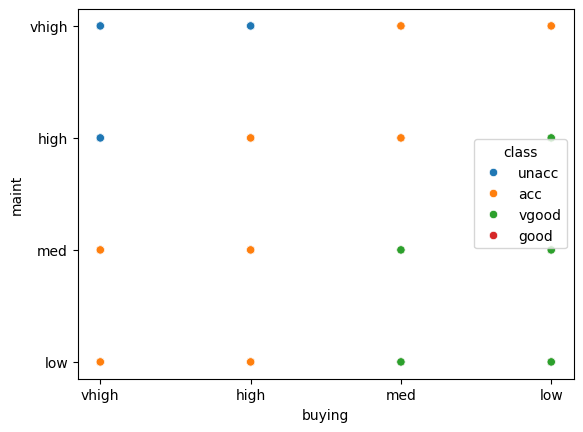

In [31]:
sns.scatterplot(x=df["buying"],y=df["maint"],hue=df["class"])
plt.show()

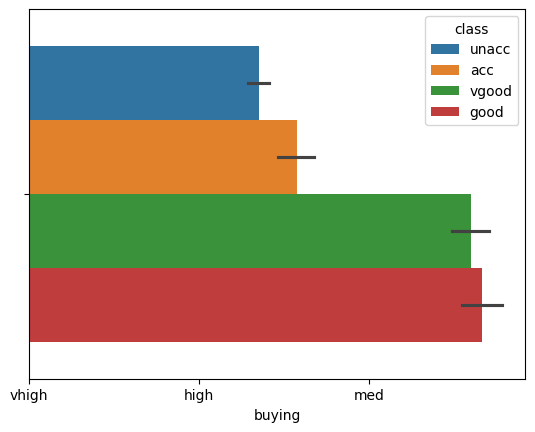

In [32]:
sns.barplot(x=df["buying"],hue=df["class"])
plt.show()

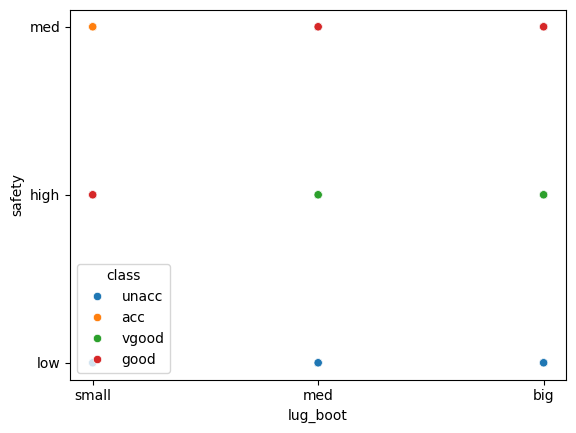

In [35]:
sns.scatterplot(x=df["lug_boot"],y=df["safety"],hue=df["class"])
plt.show()

In [37]:
#encoding
X=df.drop("class",axis=1)
y=df["class"]

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=15)

In [40]:
X_train.shape

(1208, 6)

In [43]:
#ordinal encoding neden kullandık
#lise lisans y.lisana gibi kategori yükseldikte bir mantık var
#low 1 med 2 high 3 v.high a 4 ver gibi 
#rakam yükseldikte kategorinin yükselmesinin mantıgı oldugundan dolayı

In [ ]:
df["buying"]

In [44]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [55]:
categorical_cols = ["buying","maint","lug_boot","safety"]
numerical_cols = ["doors","persons"]
#categories'ı auto bırakırsak kendısı anlamaya calısıyor fakat burada vhıgh gibi cokda anlamlandıramayacagı durumlar var kendımız yapalım o yüzde.

ordinal_encoder = OrdinalEncoder(categories=[
    ["low","med","high","vhigh"],#buying
    ["low","med","high","vhigh"],#maint
    ["small","med","big"],#lug_boot
    ["low","med","high"] #safety
])
#cok önemli
preprocessor = ColumnTransformer(
    transformers=[
        ("transformation_name_doesnt_matter",
        ordinal_encoder,
        categorical_cols),
    ],
    #bunu yazmayı unutma açıkla.dropta encode etmedıklerını düşürür
    remainder="passthrough"
)
#ordonel encoder.fit yapsak olıyor fakat bileceğiz
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [58]:
pd.DataFrame(X_train_transformed)[4].unique()

array([3., 5., 2., 4.])

In [49]:
for col in categorical_cols:
    print(df[col].value_counts())

buying
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
maint
high     432
med      432
low      432
vhigh    431
Name: count, dtype: int64
lug_boot
med      576
big      576
small    575
Name: count, dtype: int64
safety
med     576
high    576
low     575
Name: count, dtype: int64


In [64]:
#ağaç eğitimi
from sklearn.tree import DecisionTreeClassifier

In [67]:
tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=0
)#default:gini,digerparamterler ayrımı neye göre yapacagı.
#max_depth kğçük örnekler içinde dallama yapar overfiting riski var
#detayları açıkla

In [68]:
tree_model.fit(X_train_transformed,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [69]:
y_pred = tree_model.predict(X_test_transformed)

In [70]:
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

In [72]:
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))
#biraz dandik bir çıktı verdi :D bunu iyileştirmemiz lazım
#hyperpremuter ile

0.7861271676300579
[[ 62   0  59   0]
 [ 21   0   0   0]
 [ 10   0 346   0]
 [ 21   0   0   0]]
              precision    recall  f1-score   support

         acc       0.54      0.51      0.53       121
        good       0.00      0.00      0.00        21
       unacc       0.85      0.97      0.91       356
       vgood       0.00      0.00      0.00        21

    accuracy                           0.79       519
   macro avg       0.35      0.37      0.36       519
weighted avg       0.71      0.79      0.75       519



/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


[Text(0.3333333333333333, 0.875, 'persons <= 3.0\ngini = 0.451\nsamples = 1208\nvalue = [263, 48, 853, 44]'),
 Text(0.16666666666666666, 0.625, 'gini = 0.0\nsamples = 409\nvalue = [0, 0, 409, 0]'),
 Text(0.25, 0.75, 'True  '),
 Text(0.5, 0.625, 'safety <= 0.5\ngini = 0.576\nsamples = 799\nvalue = [263, 48, 444, 44]'),
 Text(0.41666666666666663, 0.75, '  False'),
 Text(0.3333333333333333, 0.375, 'gini = 0.0\nsamples = 269\nvalue = [0, 0, 269, 0]'),
 Text(0.6666666666666666, 0.375, 'buying <= 1.5\ngini = 0.63\nsamples = 530\nvalue = [263, 48, 175, 44]'),
 Text(0.5, 0.125, 'gini = 0.647\nsamples = 270\nvalue = [142, 48, 36, 44]'),
 Text(0.8333333333333334, 0.125, 'gini = 0.498\nsamples = 260\nvalue = [121, 0, 139, 0]')]

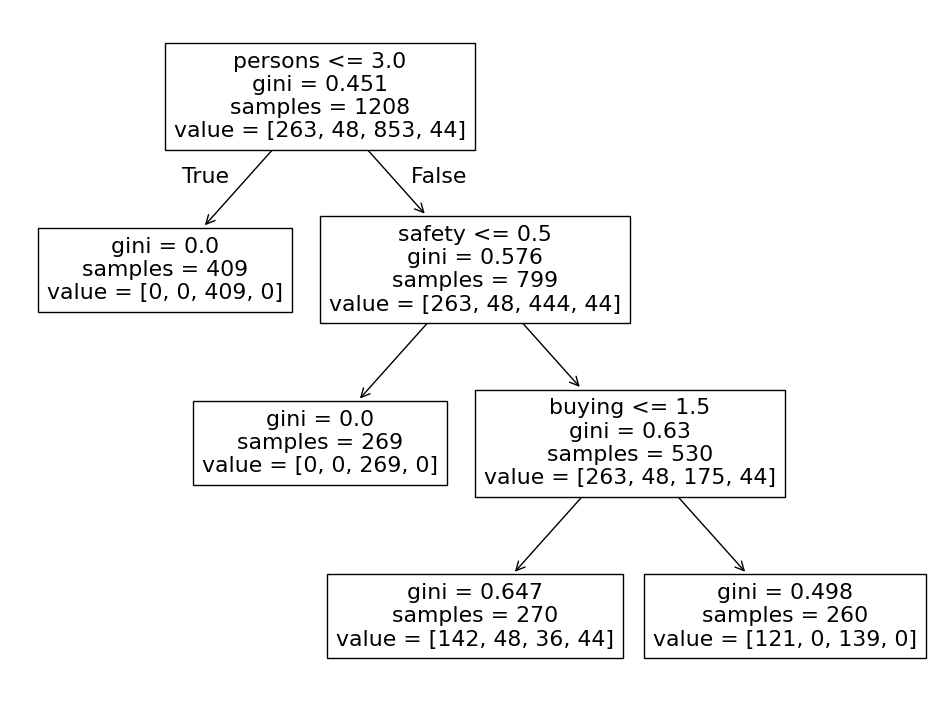

In [76]:
plt.figure(figsize=(12,9))
from sklearn import tree
column_name = categorical_cols + numerical_cols
tree.plot_tree(tree_model.fit(X_train_transformed,y_train),
              feature_names=column_name)

In [77]:
#hyperparameter tuning

In [78]:
param = {
    "criterion":["gini","entropy","log_loss"],
    "splitter":["best","random"],
    "max_depth":[1,2,3,4,5,15,None],
    "max_features":["sqrt","log2",None]
}

In [79]:
from sklearn.model_selection import GridSearchCV

In [80]:
grid = GridSearchCV(estimator=DecisionTreeClassifier(),param_grid=param,
                   cv=5,scoring="accuracy")

In [85]:
import warnings
warnings.filterwarnings("ignore")
grid.fit(X_train_transformed,y_train)

,estimator,DecisionTreeClassifier()
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'max_depth': [1, 2, ...], 'max_features': ['sqrt', 'log2', ...], 'splitter': ['best', 'random']}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'log_loss'


In [84]:
grid.best_params_

{'criterion': 'entropy',
 'max_depth': None,
 'max_features': None,
 'splitter': 'best'}

In [86]:
y_pred = grid.predict(X_test_transformed)

In [87]:
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9653179190751445
[[111   0   9   1]
 [  1  20   0   0]
 [  7   0 349   0]
 [  0   0   0  21]]
              precision    recall  f1-score   support

         acc       0.93      0.92      0.93       121
        good       1.00      0.95      0.98        21
       unacc       0.97      0.98      0.98       356
       vgood       0.95      1.00      0.98        21

    accuracy                           0.97       519
   macro avg       0.97      0.96      0.96       519
weighted avg       0.97      0.97      0.97       519



In [88]:
tree_model_new = DecisionTreeClassifier(max_depth=None,
                                       criterion="entropy",
                                       max_features=None,
                                       splitter="best")

In [89]:
tree_model_new.fit(X_train_transformed,y_train)
y_pred = tree_model_new.predict(X_test_transformed)
print(accuracy_score(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))

0.9730250481695568
[[119   0   1   1]
 [  3  18   0   0]
 [  9   0 347   0]
 [  0   0   0  21]]
              precision    recall  f1-score   support

         acc       0.91      0.98      0.94       121
        good       1.00      0.86      0.92        21
       unacc       1.00      0.97      0.99       356
       vgood       0.95      1.00      0.98        21

    accuracy                           0.97       519
   macro avg       0.97      0.95      0.96       519
weighted avg       0.97      0.97      0.97       519



[Text(0.6140202702702703, 0.9615384615384616, 'persons <= 3.0\nentropy = 1.192\nsamples = 1208\nvalue = [263, 48, 853, 44]'),
 Text(0.6005067567567568, 0.8846153846153846, 'entropy = 0.0\nsamples = 409\nvalue = [0, 0, 409, 0]'),
 Text(0.6072635135135136, 0.9230769230769231, 'True  '),
 Text(0.6275337837837838, 0.8846153846153846, 'safety <= 0.5\nentropy = 1.473\nsamples = 799\nvalue = [263, 48, 444, 44]'),
 Text(0.620777027027027, 0.9230769230769231, '  False'),
 Text(0.6140202702702703, 0.8076923076923077, 'entropy = 0.0\nsamples = 269\nvalue = [0, 0, 269, 0]'),
 Text(0.6410472972972973, 0.8076923076923077, 'buying <= 1.5\nentropy = 1.641\nsamples = 530\nvalue = [263, 48, 175, 44]'),
 Text(0.40371621621621623, 0.7307692307692307, 'maint <= 1.5\nentropy = 1.745\nsamples = 270\nvalue = [142, 48, 36, 44]'),
 Text(0.19932432432432431, 0.6538461538461539, 'safety <= 1.5\nentropy = 1.805\nsamples = 134\nvalue = [43, 48, 8, 35]'),
 Text(0.08108108108108109, 0.5769230769230769, 'lug_boot <= 0

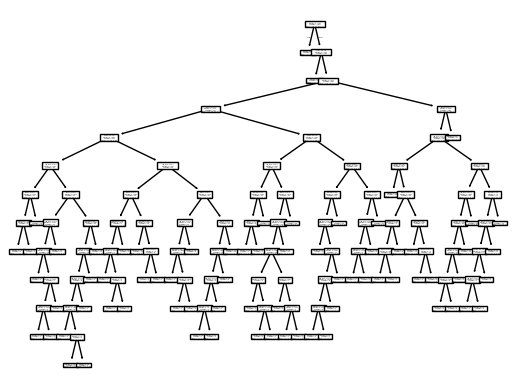

In [90]:
tree.plot_tree(tree_model_new.fit(X_train_transformed,y_train),
              feature_names=column_name)